# Extended Data Figure 5D–E — codon–anticodon RMSD and N30–U35 distance distributions

Distance: eIF5 N30 side-chain N (ND2; NZ/NE2 in N30K/N30Q) to tRNAi U35 O2 (`:1912`).

Data: `../data/rmsd/`, `../data/distance/`

In [1]:
from pathlib import Path
FIG_DIR = Path('figures'); FIG_DIR.mkdir(exist_ok=True)
TABLE_DIR = Path('tables'); TABLE_DIR.mkdir(exist_ok=True)

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from typing import Dict, List, Tuple, Optional
import re
from scipy import stats
from scipy.signal import savgol_filter

# Set plotting style
plt.rcParams['figure.figsize'] = (14, 8)
plt.rcParams['font.size'] = 11
plt.rcParams['xtick.direction'] = 'out'
plt.rcParams['ytick.direction'] = 'out'

## Configuration

In [3]:
# ============================================================
# CONFIGURATION
# ============================================================

# Data directory
DATA_DIR = Path('../data/rmsd')

# Time conversion
TIME_STEP = 0.1  # ns per frame

# Frame ranges
PLOT_START_FRAME = 0
PLOT_END_FRAME = 23000

# Bar plot figure size (width, height) per subplot
BAR_SUBPLOT_SIZE = (4, 4)

# Positions to analyze
POSITIONS = ['codon_anticodon_pos1', 
             'codon_anticodon_pos2', 
             'codon_anticodon_pos3', 
             'anticodon_stem',
             'anticodon_stem_heavy', 
             'codon_anticodon', 
             'codon_anticodon_heavy', 
             'codon_anticodon_eIF5_GNG',
             'eIF5_GNG',
             'anticodon',
             'codon']
POSITION_LABELS = {
    'codon_anticodon_pos1': 'Position 1 (First Base Pair)',
    'codon_anticodon_pos2': 'Position 2 (Second Base Pair)',
    'codon_anticodon_pos3': 'Position 3 (Wobble)', 
    'anticodon_stem': 'Anticodon Stem',
    'anticodon_stem_heavy': 'Anticodon Stem (Heavy)',
    'codon_anticodon': 'Codon-Anticodon',
    'codon_anticodon_heavy': 'Codon-Anticodon (Heavy)',
    'codon_anticodon_eIF5_GNG' : 'codon_anticodon_eIF5_GNG',
    'eIF5_GNG' : 'eIF5_GNG loop',
    'anticodon' : 'tRNAi anticodon',
    'codon' : 'mRNA start codon'
}

# System definitions
SYSTEMS = [
    'eIF5wt_AUG', 'eIF5wt_ACG', 'eIF5wt_CUG', 'eIF5wt_UUG', 'eIF5wt_AUC',
    'eIF5wt_GUG', 'eIF5_N30K_AUG', 'eIF5_N30Q_AUG', 'eIF5_G29A_G31A_AUG'
]
SYSTEM_LABELS = {
    'eIF5wt_AUG': 'wt/AUG',
    'eIF5wt_ACG': 'wt/ACG',
    'eIF5wt_CUG': 'wt/CUG',
    'eIF5wt_UUG': 'wt/UUG',
    'eIF5wt_AUC': 'wt/AUC',
    'eIF5_N30K_AUG': 'N30K/AUG',
    'eIF5_N30Q_AUG': 'N30Q/AUG',
    'eIF5_G29A_G31A_AUG': 'G29A_G31A/AUG',
    'eIF5wt_GUG': 'wt/GUG',
}

# Control system for statistical testing
CONTROL_SYSTEM = 'eIF5wt_AUG'

# Number of clones
N_CLONES = 8

# Color palette for systems (keys match SYSTEMS list)
SYSTEM_COLORS_MAP = {
    'eIF5wt_AUG': '#002849',
    'eIF5wt_ACG': '#6daa48',
    'eIF5wt_CUG': '#2ba7d8',
    'eIF5wt_UUG': '#6a3a74',
    'eIF5wt_AUC': '#faa41a',
    'eIF5wt_GUG': '#d62728',
    'eIF5_N30K_AUG': '#067f92',
    'eIF5_N30Q_AUG': '#3954a4',
    'eIF5_G29A_G31A_AUG': '#f37039'
}

## Data Loading Functions

In [4]:
def parse_filename(filename: str, positions: List[str] = POSITIONS) -> Optional[Dict[str, str]]:
    """
    Extract system information from RMSD filename.

    Args:
        filename: RMSD data filename
        positions: List of valid position names to match

    Returns:
        Dictionary with date, variant, codon, clone, position, and system keys.
        Returns None if filename does not match expected pattern.
    """
    # Build position pattern dynamically from POSITIONS list
    escaped_positions = [re.escape(pos) for pos in positions]
    position_pattern = '|'.join(escaped_positions)

    pattern = rf'(\d{{8}})_48S_(eIF5.*?)_(AUG|ACG|CUG|UUG|AUC|GUG)_clone(\d+)-({position_pattern})-rmsd\.dat'
    match = re.match(pattern, filename)

    if match:
        variant = match.group(2)
        codon = match.group(3)
        return {
            'date': match.group(1),
            'variant': variant,
            'codon': codon,
            'clone': match.group(4),
            'position': match.group(5),
            'system': f"{variant}_{codon}"
        }
    return None


def load_rmsd_file(filepath: Path) -> np.ndarray:
    """
    Load RMSD data from a single file.

    Args:
        filepath: Path to RMSD .dat file

    Returns:
        Array of RMSD values (in Angstroms)
    """
    data = np.loadtxt(filepath, skiprows=1, usecols=1)
    return data


def load_codon_anticodon_rmsd(positions: List[str] = POSITIONS) -> Dict[str, Dict[str, Dict[str, np.ndarray]]]:
    """
    Load all codon_anticodon position RMSD files.

    Args:
        positions: List of position names to load

    Returns:
        Nested dictionary: system -> position -> clone -> rmsd_array
    """
    rmsd_data: Dict[str, Dict[str, Dict[str, np.ndarray]]] = {}

    # Load files for each position in the POSITIONS list
    for position in positions:
        for filepath in sorted(DATA_DIR.glob(f'*-{position}-rmsd.dat')):
            info = parse_filename(filepath.name, positions)
            if info is None:
                continue

            system = info['system']
            pos = info['position']
            clone = info['clone']

            # Initialize nested dictionaries
            if system not in rmsd_data:
                rmsd_data[system] = {}
            if pos not in rmsd_data[system]:
                rmsd_data[system][pos] = {}

            rmsd_data[system][pos][clone] = load_rmsd_file(filepath)

    return rmsd_data


# Load all data
print("Loading dat files...")
all_data = load_codon_anticodon_rmsd()
print(f"Loaded {len(all_data)} systems")
for system in SYSTEMS:
    if system in all_data:
        n_clones = len(list(all_data[system].values())[0]) if all_data[system] else 0
        n_positions = len(all_data[system])
        print(f"  {system}: {n_clones} clones, {n_positions} positions")

Loading dat files...


Loaded 9 systems
  eIF5wt_AUG: 8 clones, 11 positions
  eIF5wt_ACG: 8 clones, 11 positions
  eIF5wt_CUG: 8 clones, 11 positions
  eIF5wt_UUG: 8 clones, 11 positions
  eIF5wt_AUC: 8 clones, 11 positions
  eIF5wt_GUG: 8 clones, 11 positions
  eIF5_N30K_AUG: 8 clones, 11 positions
  eIF5_N30Q_AUG: 8 clones, 11 positions
  eIF5_G29A_G31A_AUG: 8 clones, 11 positions


In [5]:
def calculate_replicate_means(
    all_data: Dict[str, Dict[str, Dict[str, np.ndarray]]],
    start_frame: int,
    end_frame: int
) -> pd.DataFrame:
    """
    Calculate mean RMSD for each replicate over specified frame range.
    
    Args:
        all_data: Complete RMSD dataset
        start_frame: First frame for averaging
        end_frame: Last frame for averaging
        
    Returns:
        DataFrame with System, Position, Clone, Mean_RMSD columns
    """
    results = []
    
    for system in SYSTEMS:
        if system not in all_data:
            continue
            
        for position in POSITIONS:
            if position not in all_data[system]:
                continue
                
            for clone_id, rmsd_values in all_data[system][position].items():
                mean_rmsd = np.mean(rmsd_values[start_frame:end_frame])
                
                results.append({
                    'System': system,
                    'Position': position,
                    'Clone': clone_id,
                    'Mean_RMSD': mean_rmsd
                })
    
    return pd.DataFrame(results)

In [6]:
# ============================================================
# ANALYSIS CONFIGURATION
# Set the frame range for bar plot analysis (after equilibration)
# ============================================================

ANALYSIS_START_FRAME = 13000   # Start frame (after equilibration)
ANALYSIS_END_FRAME = 23000    # End frame

print(f"Analysis Frame Range:")
print(f"  Start: {ANALYSIS_START_FRAME} ({ANALYSIS_START_FRAME * TIME_STEP:.0f} ns)")
print(f"  End:   {ANALYSIS_END_FRAME} ({ANALYSIS_END_FRAME * TIME_STEP:.0f} ns)")
print(f"  Duration: {(ANALYSIS_END_FRAME - ANALYSIS_START_FRAME) * TIME_STEP:.0f} ns")

Analysis Frame Range:
  Start: 13000 (1300 ns)
  End:   23000 (2300 ns)
  Duration: 1000 ns


## Extended Fig. 5D — Violin plots
Frames pooled across clones; points = per-clone medians.

### Codon–anticodon RMSD (heavy atoms)

In [7]:
def plot_violin(
    all_data: Dict[str, Dict[str, Dict[str, np.ndarray]]],
    selected_positions: List[str],
    selected_systems: List[str],
    start_frame: int = ANALYSIS_START_FRAME,
    end_frame: int = ANALYSIS_END_FRAME,
    figsize: Tuple[float, float] = BAR_SUBPLOT_SIZE
) -> plt.Figure:
    """
    Violin plots of pooled frame RMSD per system, one subplot per position,
    with per-clone medians overlaid.

    Args:
        all_data: Complete RMSD dataset (system -> position -> clone -> rmsd_array)
        selected_positions: List of positions to plot
        selected_systems: List of systems to include
        start_frame: First frame of analysis window
        end_frame: Last frame of analysis window
        figsize: Figure size per subplot as (width, height)

    Returns:
        Figure
    """
    n_positions = len(selected_positions)
    n_cols = min(n_positions, 3)
    n_rows = int(np.ceil(n_positions / n_cols))

    fig, axes = plt.subplots(n_rows, n_cols, figsize=(figsize[0] * n_cols, figsize[1] * n_rows), squeeze=False)
    axes = axes.flatten()

    palette = {s: SYSTEM_COLORS_MAP.get(s, '#888888') for s in selected_systems}
    x = np.arange(len(selected_systems))

    for idx, position in enumerate(selected_positions):
        ax = axes[idx]

        # Long-format frame-level data for this position
        frames = []
        for system in selected_systems:
            for clone_id, rmsd_values in all_data.get(system, {}).get(position, {}).items():
                frames.append(pd.DataFrame({
                    'System': system,
                    'Clone': clone_id,
                    'RMSD': rmsd_values[start_frame:end_frame]
                }))
        frame_df = pd.concat(frames, ignore_index=True)
        clone_medians = frame_df.groupby(['System', 'Clone'])['RMSD'].median()

        # Pooled frame distributions
        sns.violinplot(data=frame_df, x='System', y='RMSD', hue='System',
                       order=selected_systems, hue_order=selected_systems,
                       palette=palette, cut=0, density_norm='width',
                       inner=None, linewidth=0.5, legend=False, ax=ax)

        # Per-clone medians as jitter points
        for i, system in enumerate(selected_systems):
            if system not in clone_medians.index.get_level_values('System'):
                continue
            medians = clone_medians.loc[system].values
            np.random.seed(42)
            x_jitter = np.random.normal(i, 0.05, size=len(medians))
            ax.scatter(x_jitter, medians,
                       color='black', s=20, alpha=1.0, zorder=5,
                       edgecolors='white', linewidths=0.5)

        # Formatting
        ax.set_xlabel('System', fontsize=11)
        ax.set_ylabel('RMSD (Å)', fontsize=11)
        ax.set_title(POSITION_LABELS.get(position, position), fontsize=12, fontweight='bold')
        ax.set_xticks(x)
        ax.set_xticklabels([SYSTEM_LABELS.get(s, s) for s in selected_systems],
                           rotation=45, ha='right', fontsize=9)
        ax.set_ylim(bottom=0)
        ax.spines['top'].set_visible(False)
        ax.spines['right'].set_visible(False)
        ax.grid(False)
        ax.tick_params(axis='both', which='major', direction='out', length=6, width=1,
                       color='black', labelcolor='black')

    # Hide unused subplots
    for idx in range(n_positions, len(axes)):
        axes[idx].set_visible(False)

    plt.tight_layout()
    return fig

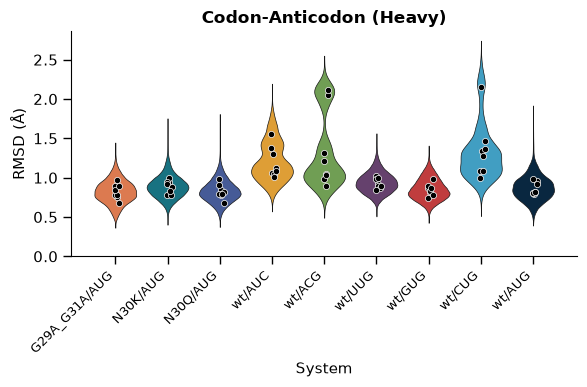

In [8]:
fig = plot_violin(
    all_data,
    ['codon_anticodon_heavy'],
    np.flip(['eIF5wt_AUG', 'eIF5wt_CUG', 'eIF5wt_GUG', 'eIF5wt_UUG', 'eIF5wt_ACG', 'eIF5wt_AUC', 'eIF5_N30Q_AUG', 'eIF5_N30K_AUG', 'eIF5_G29A_G31A_AUG']),
    figsize=(6, 4)
)

plt.savefig(FIG_DIR / "ExtFig5D_codon_anticodon_rmsd_violin.png", dpi=150, transparent=True)
plt.show()

### N30–U35 distance

In [9]:
DATA_DIR = Path('../data/distance')
DISTANCE_LABEL = 'N30-ND2_tRNAi-U2054-O2'
TIME_STEP = 0.1  # ns/frame
PLOT_START_FRAME = 0
PLOT_END_FRAME = 22000
SG_WINDOW = 1000  # savgol_filter window (matches rmsd_analysis.ipynb's GNG time series)
SG_POLYORDER = 3

# System definitions (matches rmsd_analysis.ipynb)
SYSTEMS = [
    'eIF5wt_AUG', 'eIF5wt_ACG', 'eIF5wt_CUG', 'eIF5wt_UUG', 'eIF5wt_AUC',
    'eIF5wt_GUG', 'eIF5_N30K_AUG', 'eIF5_N30Q_AUG', 'eIF5_G29A_G31A_AUG'
]
SYSTEM_LABELS = {
    'eIF5wt_AUG': 'wt/AUG',
    'eIF5wt_ACG': 'wt/ACG',
    'eIF5wt_CUG': 'wt/CUG',
    'eIF5wt_UUG': 'wt/UUG',
    'eIF5wt_AUC': 'wt/AUC',
    'eIF5wt_GUG': 'wt/GUG',
    'eIF5_N30K_AUG': 'N30K/AUG',
    'eIF5_N30Q_AUG': 'N30Q/AUG',
    'eIF5_G29A_G31A_AUG': 'G29A_G31A/AUG',
}

N_CLONES = 8

In [10]:
def parse_filename(filename: str) -> Optional[Dict[str, str]]:
    pattern = r'(\d{8})_48S_(eIF5.*?)_(AUG|ACG|CUG|UUG|AUC|GUG)_clone(\d+)-eIF5-(.*?)-distance\.dat'
    match = re.match(pattern, filename)
    if not match:
        return None
    date, variant, codon, clone, distance_type = match.groups()
    return {
        'date': date,
        'variant': variant,
        'codon': codon,
        'clone': clone,
        'distance_type': distance_type,
        'system': f'{variant}_{codon}',
    }

In [11]:
def load_distance_file(filepath: Path) -> np.ndarray:
    return np.loadtxt(filepath, skiprows=1, usecols=1)


def load_all_distances() -> Dict[str, Dict[str, np.ndarray]]:
    """Returns system -> clone -> distance array, filtered to DISTANCE_LABEL."""
    data: Dict[str, Dict[str, np.ndarray]] = {}
    for filepath in sorted(DATA_DIR.glob(f'*-eIF5-{DISTANCE_LABEL}-distance.dat')):
        info = parse_filename(filepath.name)
        if info is None:
            print(f'Warning: could not parse {filepath.name}')
            continue
        data.setdefault(info['system'], {})[info['clone']] = load_distance_file(filepath)
    return data


all_data = load_all_distances()
print(f'Loaded {len(all_data)} systems:')
for system, clones in sorted(all_data.items()):
    print(f'  {system}: {len(clones)} clones')

Loaded 9 systems:
  eIF5_G29A_G31A_AUG: 8 clones
  eIF5_N30K_AUG: 8 clones
  eIF5_N30Q_AUG: 8 clones
  eIF5wt_ACG: 8 clones
  eIF5wt_AUC: 8 clones
  eIF5wt_AUG: 8 clones
  eIF5wt_CUG: 8 clones
  eIF5wt_GUG: 8 clones
  eIF5wt_UUG: 8 clones


In [12]:
# ============================================================
# ANALYSIS CONFIGURATION
# Set the frame range for bar plot analysis (after equilibration)
# ============================================================

ANALYSIS_START_FRAME = 13000   # Start frame (after equilibration)
ANALYSIS_END_FRAME = 23000    # End frame
CONTACT_CUTOFF = 3.5  # Å, N30-ND2...U2054-O2 contact cutoff

# Bar plot figure size (width, height) per subplot
BAR_SUBPLOT_SIZE = (4, 4)

# Control system for statistical testing
CONTROL_SYSTEM = 'eIF5wt_AUG'

# Color palette for systems (matches rmsd_analysis.ipynb)
SYSTEM_COLORS_MAP = {
    'eIF5wt_AUG': '#002849',
    'eIF5wt_ACG': '#6daa48',
    'eIF5wt_CUG': '#2ba7d8',
    'eIF5wt_UUG': '#6a3a74',
    'eIF5wt_AUC': '#faa41a',
    'eIF5wt_GUG': '#d62728',
    'eIF5_N30K_AUG': '#067f92',
    'eIF5_N30Q_AUG': '#3954a4',
    'eIF5_G29A_G31A_AUG': '#f37039'
}

METRICS = ['Contact_Fraction', 'Mean_Distance']
METRIC_LABELS = {
    'Contact_Fraction': f'Fraction of frames < {CONTACT_CUTOFF} Å',
    'Mean_Distance': 'Mean distance (Å)',
}

print(f"Analysis Frame Range:")
print(f"  Start: {ANALYSIS_START_FRAME} ({ANALYSIS_START_FRAME * TIME_STEP:.0f} ns)")
print(f"  End:   {ANALYSIS_END_FRAME} ({ANALYSIS_END_FRAME * TIME_STEP:.0f} ns)")
print(f"  Duration: {(ANALYSIS_END_FRAME - ANALYSIS_START_FRAME) * TIME_STEP:.0f} ns")

Analysis Frame Range:
  Start: 13000 (1300 ns)
  End:   23000 (2300 ns)
  Duration: 1000 ns


In [13]:
def build_frame_df(
    all_data: Dict[str, Dict[str, np.ndarray]],
    selected_systems: List[str],
    start_frame: int = ANALYSIS_START_FRAME,
    end_frame: int = ANALYSIS_END_FRAME
) -> pd.DataFrame:
    """
    Build a long-format frame-level DataFrame for the selected systems.

    Args:
        all_data: system -> clone -> distance array
        selected_systems: List of systems to include
        start_frame: First frame of analysis window
        end_frame: Last frame of analysis window

    Returns:
        DataFrame with System, Clone, Distance columns (one row per frame)
    """
    frames = []
    for system in selected_systems:
        for clone_id, distances in all_data.get(system, {}).items():
            dist_slice = distances[start_frame:end_frame]
            frames.append(pd.DataFrame({
                'System': system,
                'Clone': clone_id,
                'Distance': dist_slice
            }))
    return pd.concat(frames, ignore_index=True)


def plot_distance_violin(
    all_data: Dict[str, Dict[str, np.ndarray]],
    selected_systems: List[str],
    cutoff: float = CONTACT_CUTOFF,
    figsize: Tuple[float, float] = BAR_SUBPLOT_SIZE
) -> plt.Figure:
    """
    Violin plot of pooled frame distances per system with per-clone medians overlaid.

    Args:
        all_data: system -> clone -> distance array
        selected_systems: List of systems to include
        cutoff: H-bond contact cutoff (Å) drawn as a dashed line
        figsize: Figure size as (width, height)

    Returns:
        Figure
    """
    frame_df = build_frame_df(all_data, selected_systems)
    clone_medians = frame_df.groupby(['System', 'Clone'])['Distance'].median()

    fig, ax = plt.subplots(figsize=figsize)
    x = np.arange(len(selected_systems))

    # Pooled frame distributions
    sns.violinplot(data=frame_df, x='System', y='Distance', hue='System',
                   order=selected_systems, hue_order=selected_systems,
                   palette={s: SYSTEM_COLORS_MAP.get(s, '#888888') for s in selected_systems},
                   cut=0, density_norm='width', inner=None, linewidth=0.5,
                   legend=False, ax=ax)

    # Per-clone medians as jitter points
    for i, system in enumerate(selected_systems):
        if system not in clone_medians.index.get_level_values('System'):
            continue
        medians = clone_medians.loc[system].values
        np.random.seed(42)
        x_jitter = np.random.normal(i, 0.05, size=len(medians))
        ax.scatter(x_jitter, medians,
                   color='black', s=20, alpha=1.0, zorder=5,
                   edgecolors='white', linewidths=0.5)

    ax.axhline(cutoff, color='black', linestyle='--', linewidth=1, zorder=4)

    # Formatting
    ax.set_xlabel('System', fontsize=11)
    ax.set_ylabel('Distance (Å)', fontsize=11)
    ax.set_xticks(x)
    ax.set_xticklabels([SYSTEM_LABELS.get(s, s) for s in selected_systems],
                       rotation=45, ha='right', fontsize=9)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.grid(False)
    ax.tick_params(axis='both', which='major', direction='out', length=6, width=1,
                   color='black', labelcolor='black')

    ax.set_title(f'eIF5-N30-ND2 — tRNAi-U2054-O2\n[Frames {ANALYSIS_START_FRAME}-{ANALYSIS_END_FRAME}]',
                 fontsize=11, fontweight='bold')
    plt.tight_layout()
    return fig

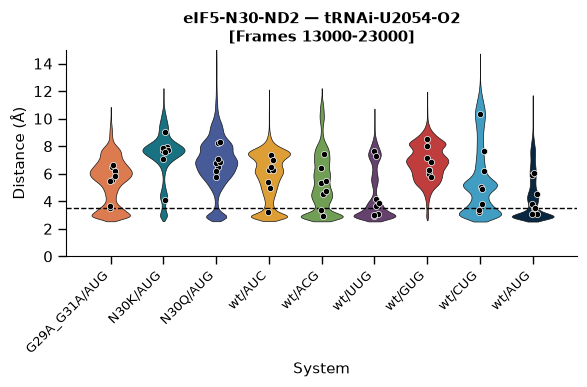

In [14]:
fig = plot_distance_violin(all_data,
                           np.flip(['eIF5wt_AUG', 'eIF5wt_CUG', 'eIF5wt_GUG', 'eIF5wt_UUG', 
                                    'eIF5wt_ACG', 'eIF5wt_AUC', 'eIF5_N30Q_AUG', 'eIF5_N30K_AUG', 'eIF5_G29A_G31A_AUG']), 
                                   figsize=(6, 4))
fig.axes[0].set_ylim([0, 15])
fig.axes[0].set_yticks(np.arange(0, 16, 2))

plt.savefig(FIG_DIR / "ExtFig5D_N30_U35_distance_violin.png", dpi=150, transparent=True)
plt.show()



## Extended Fig. 5E — 2D distribution: codon–anticodon RMSD vs N30–U35 distance

In [15]:
RMSD_DIR = Path('../data/rmsd')
RMSD_POSITION = 'codon_anticodon_eIF5_GNG'
LANDSCAPE_STRIDE = 20  # plot every 20th frame (matches 2023-04-19_plot_MD_data.ipynb)
LANDSCAPE_SYSTEMS = ['eIF5wt_AUG', 'eIF5wt_CUG', 'eIF5wt_GUG', 'eIF5wt_UUG',
                     'eIF5wt_ACG', 'eIF5wt_AUC', 'eIF5_N30Q_AUG', 'eIF5_N30K_AUG', 'eIF5_G29A_G31A_AUG']
LANDSCAPE_XLIM = (0, 14)  # distance, Å
LANDSCAPE_YLIM = (0, 3)   # RMSD, Å


def load_all_rmsd(position: str = RMSD_POSITION) -> Dict[str, Dict[str, np.ndarray]]:
    """Returns system -> clone -> RMSD array for one RMSD position."""
    data: Dict[str, Dict[str, np.ndarray]] = {}
    pattern = rf'(\d{{8}})_48S_(eIF5.*?)_(AUG|ACG|CUG|UUG|AUC|GUG)_clone(\d+)-{re.escape(position)}-rmsd\.dat'
    for filepath in sorted(RMSD_DIR.glob(f'*-{position}-rmsd.dat')):
        match = re.match(pattern, filepath.name)
        if match is None:
            continue
        _, variant, codon, clone = match.groups()
        data.setdefault(f'{variant}_{codon}', {})[clone] = np.loadtxt(filepath, skiprows=1, usecols=1)
    return data


def plot_distance_rmsd_landscape(
    distance_data: Dict[str, Dict[str, np.ndarray]],
    rmsd_data: Dict[str, Dict[str, np.ndarray]],
    selected_systems: List[str],
    start_frame: int = ANALYSIS_START_FRAME,
    end_frame: int = ANALYSIS_END_FRAME,
    stride: int = LANDSCAPE_STRIDE,
    subplot_size: Tuple[float, float] = (2.2, 2.4),
    xlabel: str = "N30-U2054 distance, Å",
    ylabel: str = "GNG RMSD, Å",
    xlim: Tuple[float, float] = LANDSCAPE_XLIM,
    ylim: Tuple[float, float] = LANDSCAPE_YLIM
) -> plt.Figure:
    """
    Plot 2D population landscapes (distance vs. RMSD) in one row, one panel per system,
    with marginal histograms of distance (top) and RMSD (right).

    Args:
        distance_data: system -> clone -> distance array
        rmsd_data: system -> clone -> RMSD array
        selected_systems: List of systems to plot, left to right
        start_frame: First frame of analysis window
        end_frame: Last frame of analysis window
        stride: Plot every Nth frame in the 2D KDE
        subplot_size: Figure size per panel as (width, height)
        xlabel: Distance axis label
        ylabel: RMSD axis label (first panel only)
        xlim: Distance axis limits, Å
        ylim: RMSD axis limits, Å

    Returns:
        Figure
    """
    n_systems = len(selected_systems)
    fig = plt.figure(figsize=(subplot_size[0] * n_systems, subplot_size[1]))
    outer = fig.add_gridspec(1, n_systems, wspace=0.35)

    x_bins = np.linspace(*xlim, 57)
    y_bins = np.linspace(*ylim, 41)

    for idx, system in enumerate(selected_systems):
        # Pair distance and RMSD frame-by-frame within each clone, then pool clones
        clones = sorted(set(distance_data.get(system, {})) & set(rmsd_data.get(system, {})), key=int)
        x = np.concatenate([distance_data[system][c][start_frame:end_frame] for c in clones])
        y = np.concatenate([rmsd_data[system][c][start_frame:end_frame] for c in clones])
        color = SYSTEM_COLORS_MAP.get(system, '#888888')

        inner = outer[idx].subgridspec(2, 2, width_ratios=[4, 1], height_ratios=[1, 4],
                                       wspace=0.05, hspace=0.05)
        ax = fig.add_subplot(inner[1, 0])
        ax_top = fig.add_subplot(inner[0, 0], sharex=ax)
        ax_right = fig.add_subplot(inner[1, 1], sharey=ax)

        # 2D landscape
        sns.kdeplot(x=x[::stride], y=y[::stride], cmap="turbo", fill=True, levels=20, ax=ax)

        # Marginal histograms (all frames in window)
        ax_top.hist(x, bins=x_bins, density=True, color=color, histtype='stepfilled')
        ax_right.hist(y, bins=y_bins, density=True, color=color, histtype='stepfilled',
                      orientation='horizontal')
        for marginal in (ax_top, ax_right):
            marginal.axis('off')

        ax_top.set_title(SYSTEM_LABELS.get(system, system))
        ax.set_xlabel(xlabel)
        ax.set_ylabel(ylabel if idx == 0 else "")
        ax.set_xlim(xlim)
        ax.set_ylim(ylim)
        ax.set_xticks(np.arange(xlim[0], xlim[1] + 1, 4))
        ax.set_yticks(np.arange(ylim[0], ylim[1] + 1, 1))
        ax.grid(linestyle=":")

    fig.subplots_adjust(left=0.04, right=0.99, bottom=0.2, top=0.88)
    return fig


Loaded codon_anticodon_heavy RMSD for 9 systems


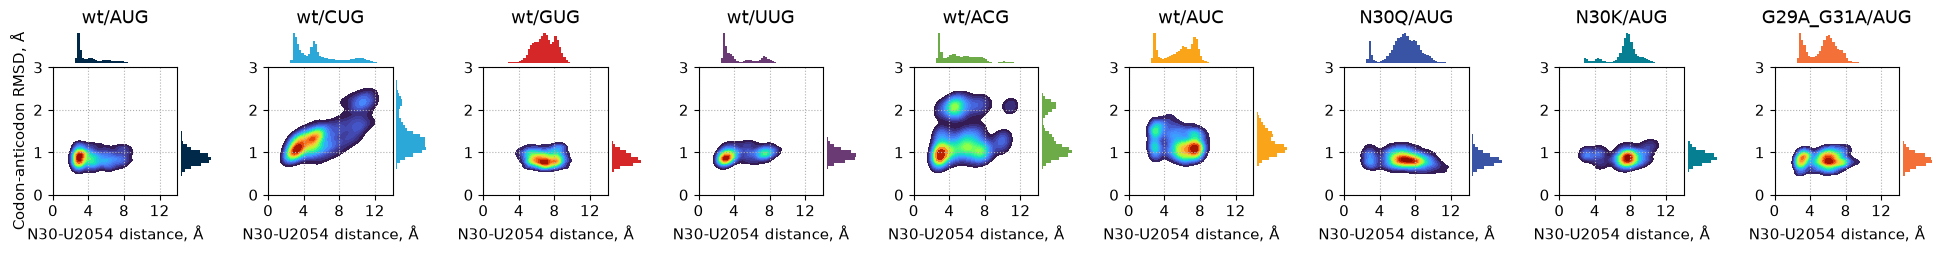

In [16]:
rmsd_ca_data = load_all_rmsd('codon_anticodon_heavy')
print(f'Loaded codon_anticodon_heavy RMSD for {len(rmsd_ca_data)} systems')

fig = plot_distance_rmsd_landscape(all_data, rmsd_ca_data, LANDSCAPE_SYSTEMS,
                                   ylabel="Codon-anticodon RMSD, Å")

plt.savefig(FIG_DIR / "ExtFig5E_landscape_codon_anticodon_rmsd_vs_distance.png", dpi=150, transparent=True)
plt.show()